In [1]:
import numpy as np
import pandas as pd
import random
import pickle
import os
import time
import warnings
import threading
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots 

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import ipywidgets as widgets
from IPython.display import display, HTML,clear_output

warnings.filterwarnings('ignore')
plt.style.use('dark_background')
pd.set_option('display.max_columns', None)
np.random.seed(42)
random.seed(42)

In [2]:
df = pd.read_csv('Smart_Irrigation.csv', sep=';')

In [3]:
df.shape

(1001, 9)

In [4]:
df.head()

,Timestamp,Station_ID,Temperature_C,Humidity_Pct,Wind_Speed_Kmh,Precipitation_mm,Solar_Radiation_W_m2,Soil_Moisture_Pct,Irrigation_Status
0,01/01/2026 05:00,YEM_HODEIDAH,23.5,78,10.0,0.0,0,33.9,1.0
1,01/01/2026 13:00,YEM_HODEIDAH,23.5,60,18.5,0.0,720,29.7,1.0
2,01/01/2026 15:00,YEM_HODEIDAH,23.5,60,18.5,0.0,720,23.9,1.0
3,01/01/2026 20:00,YEM_HODEIDAH,23.5,60,18.5,5.4,0,53.5,0.0
4,02/01/2026 03:00,YEM_HODEIDAH,23.5,78,10.0,0.0,0,44.0,0.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1001 entries, 0 to 1000
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Timestamp             1000 non-null   object 
 1   Station_ID            1000 non-null   object 
 2   Temperature_C         1000 non-null   float64
 3   Humidity_Pct          1001 non-null   int64  
 4   Wind_Speed_Kmh        1001 non-null   float64
 5   Precipitation_mm      1000 non-null   float64
 6   Solar_Radiation_W_m2  1001 non-null   int64  
 7   Soil_Moisture_Pct     1000 non-null   float64
 8   Irrigation_Status     1000 non-null   float64
dtypes: float64(5), int64(2), object(2)
memory usage: 70.5+ KB


In [6]:
df.describe()

,Temperature_C,Humidity_Pct,Wind_Speed_Kmh,Precipitation_mm,Solar_Radiation_W_m2,Soil_Moisture_Pct,Irrigation_Status
count,1000.0,1001.00000,1001.00000,1000.000000,1001.000000,1000.000000,1000.000000
mean,23.5,40.16983,11.41009,0.424800,237.022977,36.321200,0.388000
std,0.0,18.18519,3.75605,1.536198,308.519576,9.623691,0.487538
min,23.5,0.00000,0.00000,0.000000,0.000000,10.000000,0.000000
25%,23.5,25.00000,8.00000,0.000000,0.000000,29.700000,0.000000
50%,23.5,40.00000,12.00000,0.000000,0.000000,37.000000,0.000000
75%,23.5,60.00000,12.00000,0.000000,580.000000,42.000000,1.000000
max,23.5,78.00000,18.50000,12.000000,720.000000,79.300000,1.000000


In [7]:
print("Duplicates:",df.duplicated().sum())

Duplicates: 0


In [8]:
df.isnull().sum()

Timestamp               1
Station_ID              1
Temperature_C           1
Humidity_Pct            0
Wind_Speed_Kmh          0
Precipitation_mm        1
Solar_Radiation_W_m2    0
Soil_Moisture_Pct       1
Irrigation_Status       1
dtype: int64

In [9]:
numeric_cols = ['Temperature_C', 'Humidity_Pct', 'Wind_Speed_Kmh', 'Solar_Radiation_W_m2', 'Soil_Moisture_Pct']
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mean())

if 'Precipitation_mm' in df.columns:
    df['Precipitation_mm'] = df['Precipitation_mm'].fillna(0.0)

categorical_cols = ['Timestamp', 'Station_ID', 'Irrigation_Status']
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])        

In [10]:
print(df.isnull().sum())

Timestamp               0
Station_ID              0
Temperature_C           0
Humidity_Pct            0
Wind_Speed_Kmh          0
Precipitation_mm        0
Solar_Radiation_W_m2    0
Soil_Moisture_Pct       0
Irrigation_Status       0
dtype: int64


🎯 Model Accuracy: 92.54%


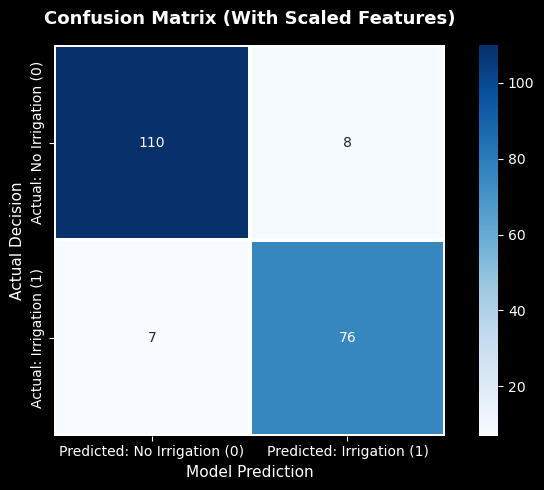

💾 Model file (smart_irrigation_model.pkl) saved successfully!
💾 Scaler file (scaler.pkl) saved successfully!
✨ Jupyter Notebook phase completed successfully!


In [11]:
X = df[['Temperature_C', 'Humidity_Pct', 'Wind_Speed_Kmh', 'Solar_Radiation_W_m2', 'Soil_Moisture_Pct']]
y = df['Irrigation_Status']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train_scaled, y_train)

from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test_scaled)
print(f"🎯 Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", linewidths=1.5, square=True,
            xticklabels=["Predicted: No Irrigation (0)", "Predicted: Irrigation (1)"],
            yticklabels=["Actual: No Irrigation (0)", "Actual: Irrigation (1)"])

plt.title("Confusion Matrix (With Scaled Features)", fontsize=13, fontweight='bold', pad=15)
plt.xlabel("Model Prediction", fontsize=11)
plt.ylabel("Actual Decision", fontsize=11)
plt.tight_layout()
plt.show()

import pickle

with open('smart_irrigation_model.pkl', 'wb') as f:
    pickle.dump(model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print("💾 Model file (smart_irrigation_model.pkl) saved successfully!")
print("💾 Scaler file (scaler.pkl) saved successfully!")
print("✨ Jupyter Notebook phase completed successfully!")
